In [1]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms, models
from tqdm import tqdm, trange
import numpy as np
from utils import save_checkpoint, load_checkpoint, train_func_classification
import matplotlib.pyplot as plt
import pathlib

d:\anaconda3\envs\CS2109S\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
from torch_influence.base import BaseObjective
from torch_influence.modules import CGInfluenceModule, LiSSAInfluenceModule, AutogradInfluenceModule

In [3]:
transform = transforms.Compose([transforms.Resize((299, 299)), transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
cifar10_train = datasets.CIFAR10('../data', train=True, download=True, transform=transform)
cifar10_test = datasets.CIFAR10('../data', train=False, download=True, transform=transform)
cifar10_train_loader = DataLoader(cifar10_train, batch_size=20, shuffle=True)
cifar10_test_loader = DataLoader(cifar10_test, batch_size=20, shuffle=True)

Files already downloaded and verified
Files already downloaded and verified


In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DOGFISH_RAW_PATH = '../data/dogfish/dataset_dog-fish_train-900_test-300.npz'
DOGFISH_EMB_PATH = '../data/dogfish/dataset_dog-fish_embeds.npz'
dogfish_raw = np.load(DOGFISH_RAW_PATH, mmap_mode='r')

class DogfishDataset(Dataset):
    def __init__(self, X, Y, transforms=None):
        self.X = X
        self.Y = Y
        self.transforms = transforms
        
    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        sample = self.X[idx]
        label = self.Y[idx].astype(np.int64)
        if self.transforms:
            sample = self.transforms(sample)
        return sample, label

# split: train or validation
def load_dogfish_examples(split, idxs):
    image = dogfish_raw[f"X_{split}"][idxs]
    label = dogfish_raw[f"Y_{split}"][idxs]
    return image, label

def dataloader_from_npz(path, type):
    data = np.load(path, "r")
    print(data)
    transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: x.permute([2, 0, 1]))]) if type == "raw" else None
    train = DataLoader(DogfishDataset(data["X_train"], data["Y_train"], transforms=transform), batch_size=20, shuffle=True)
    test = DataLoader(DogfishDataset(data["X_test"], data["Y_test"], transforms=transform), batch_size=20, shuffle=False)
    return train, test

def load_inception_embeds():
    # load pretrained Inceptionv3
    if not pathlib.Path(DOGFISH_EMB_PATH).is_file():
        model = models.inception_v3(pretrained=True, transform_input=False)
        model.fc = nn.Identity()  # remove the last layer
        model.eval()
        model = model.to(DEVICE)

        embeds = {}
        raws = {}
        for split in ("train", "test"):
            n = 2 * (900 if (split == "train") else 300)

            X_embed, Y_embed = [], []
            X_raw, Y_raw = [], []
            for idx in trange(0, n, 20, desc=f"Embedding Dogfish ({split})"):
                batch_idxs = [idx + offset for offset in range(20)]
                images, labels = load_dogfish_examples(split, batch_idxs)
                images = torch.tensor(images, dtype=torch.float32, device=DEVICE)
                images = images.permute([0, 3, 1, 2]) # move channel to the second dimension
                X_raw.append(images)
                Y_raw.append(labels)
                
                # getting Inceptionv3 embedding
                with torch.no_grad():
                    h = model(images).cpu().numpy()

                X_embed.append(h)
                Y_embed.append(labels)

            embeds[f"X_{split}"] = np.concatenate(X_embed, axis=0).astype(np.float32)
            embeds[f"Y_{split}"] = np.concatenate(Y_embed, axis=0).astype(np.float32)
        
        np.savez(DOGFISH_EMB_PATH, **embeds)
    print("Loading Dogfish embeddings")
    raw_train, raw_test = dataloader_from_npz(DOGFISH_RAW_PATH, "raw")
    embeds_train, embeds_test = dataloader_from_npz(DOGFISH_EMB_PATH, "embeds")
    return raw_train, raw_test, embeds_train, embeds_test


In [5]:
raw_train, raw_test, embeds_train, embeds_test = load_inception_embeds()

Loading Dogfish embeddings
NpzFile '../data/dogfish/dataset_dog-fish_train-900_test-300.npz' with keys: X_test, X_train, Y_train, Y_test
NpzFile '../data/dogfish/dataset_dog-fish_embeds.npz' with keys: X_train, Y_train, X_test, Y_test


In [6]:
for x, y in embeds_train:
    print(x.shape, y[0])
    break
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

torch.Size([20, 2048]) tensor(0)


In [7]:
class V3FC(nn.Module):
    def __init__(self):
        super(V3FC, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(2048, 10),
            nn.Flatten(),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.model(x)

In [8]:
def train_func_classification(model, criterion, optimizer, train_loader, validation_loader, epochs):
    train_losses = []
    accuracies = []
    checkpoints = []
    
    for epoch in range(epochs):
        model.train()
        loss = 0.0
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_pred = model(x_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            loss += loss.item()
            
        loss = loss / len(train_loader)
        train_losses.append(loss)
            
        model.eval()
        correct_count = 0
        for x_val_batch, y_val_batch in validation_loader:
            y_pred = model(x_val_batch)
            predictions = torch.argmax(y_pred, dim=-1)
            result = predictions == y_val_batch
            correct_count += result.sum()
            
        accuracy = (correct_count / len(validation_loader.dataset)).item()
        accuracies.append(accuracy)
        print(f"Epoch: {epoch + 1}, Train Loss: {loss}, accuracy: {accuracy}")
        
        if ((epoch + 1) / epochs in [0.2, 0.4, 0.6, 0.8, 1.0]) or (
            epoch > 1 and accuracies[-1] - accuracies[-2] > 0.1) or (epoch + 1 == 115):
            checkpoint_f = save_checkpoint(model, optimizer, epoch + 1, epochs, filepath=f"../checkpoint/{type(model).__name__}")
            checkpoints.append(checkpoint_f)
        
    epochs_range = range(1, epochs + 1)
    plt.figure(figsize=(10, 5))
    train_losses = [loss.detach().numpy() for loss in train_losses]
    max_accuracy = np.max(accuracies)
    min_accuracy = np.min(accuracies)
    accuracy_diff = max_accuracy - min_accuracy
    val_accuracies = [((accuracy - min_accuracy) / accuracy_diff) * (np.max(train_losses) - np.min(train_losses)) + np.min(train_losses) 
                      for accuracy in accuracies]
    plt.plot(epochs_range, train_losses, label='Train Loss')
    plt.plot(epochs_range, val_accuracies, label='Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Loss / Accuracy')
    plt.title('Train and Accuracy')
    plt.legend()
    plt.show()
    return model, checkpoints, train_losses, accuracies

Epoch: 1, Train Loss: 0.036640558391809464, accuracy: 0.6016666889190674
Epoch: 2, Train Loss: 0.0360155813395977, accuracy: 0.6850000023841858
Epoch: 3, Train Loss: 0.03570536896586418, accuracy: 0.7333333492279053
Epoch: 4, Train Loss: 0.03565675765275955, accuracy: 0.7316666841506958
Epoch: 5, Train Loss: 0.03559747710824013, accuracy: 0.7283333539962769
Epoch: 6, Train Loss: 0.03563682362437248, accuracy: 0.7049999833106995
Epoch: 7, Train Loss: 0.035581666976213455, accuracy: 0.6949999928474426
Epoch: 8, Train Loss: 0.03558344393968582, accuracy: 0.6816666722297668
Epoch: 9, Train Loss: 0.035552725195884705, accuracy: 0.6399999856948853
Epoch: 10, Train Loss: 0.03555890545248985, accuracy: 0.6066666841506958
Epoch: 11, Train Loss: 0.03555259108543396, accuracy: 0.5849999785423279
Epoch: 12, Train Loss: 0.03552643582224846, accuracy: 0.54666668176651
Epoch: 13, Train Loss: 0.03552946820855141, accuracy: 0.5266666412353516
Epoch: 14, Train Loss: 0.03552037104964256, accuracy: 0.5066

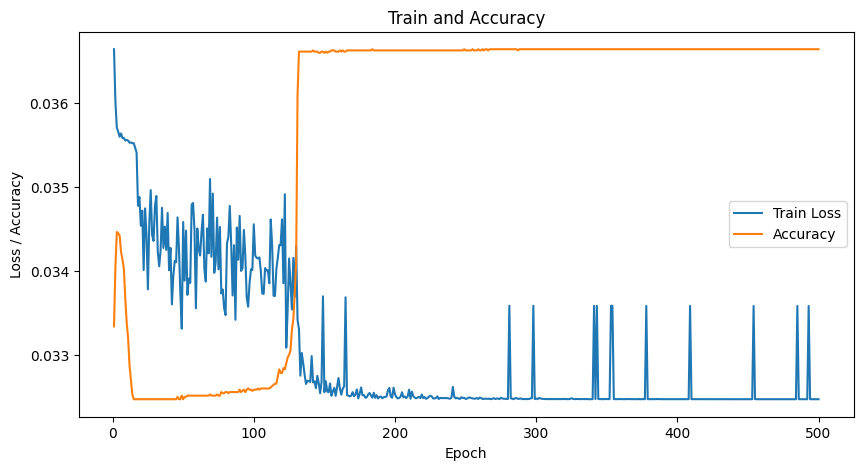

In [69]:
model = V3FC().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
model, checkpoints, train_losses, accuracies = train_func_classification(model, nn.CrossEntropyLoss(), 
torch.optim.Adam(model.parameters(), lr=0.0001), embeds_train, embeds_test, 500)

In [9]:
checkpoints = ['../checkpoint/V3FC/V3FC_epoch_100_0.2.pth',
 '../checkpoint/V3FC/V3FC_epoch_115_0.23.pth',
 '../checkpoint/V3FC/V3FC_epoch_126_0.252.pth',
 '../checkpoint/V3FC/V3FC_epoch_200_0.4.pth',
 '../checkpoint/V3FC/V3FC_epoch_300_0.6.pth',
 '../checkpoint/V3FC/V3FC_epoch_400_0.8.pth',
 '../checkpoint/V3FC/V3FC_epoch_500_1.0.pth']

In [10]:
def calculate_influence_score_nn(
    traindata: DataLoader, 
    testdata: DataLoader, 
    model, 
    criterion,
    device,
    epochs=-1,
    train_func=None,
    per_point=-1, 
    appro="cg"
    ):
    """
    Calculate influence score for each training data point
    Parameters
    ----------
    traindata: train data loader
    testdata: test data loader
    model: nn.Module
    per_point: if >= 0: return instance score for specific test point; else return instance score for test sets
    Returns
    -------

    """

    # initialize the model and optimizer
    trainidx = len(traindata.dataset)
    testidx = len(testdata.dataset)

    class NNObjective(BaseObjective):
        
        # batch: Dataset
        def train_outputs(self, model, batch):
            inputs, _ = batch
            inputs = inputs
            inputs = inputs.to(device, dtype=torch.float)
            return model(inputs)

        def train_loss_on_outputs(self, outputs, batch):
            _, labels = batch
            labels = labels
            labels = labels.to(device)
            return criterion(outputs, labels)

        def train_regularization(self, params):
            return 0

        # training loss by default taken to be
        # train_loss_on_outputs + train_regularization

        def test_loss(self, model, params, batch):
            inputs, labels = batch
            inputs = inputs.to(device, dtype=torch.float)
            labels = labels.to(device)
            return criterion(model(inputs), labels)
        
    if train_func != None:
        model, _, val_losses = train_func(
            model = model,
            criterion = criterion,
            optimizer = torch.optim.Adam(model.parameters(), lr=0.0001),
            train_loader = traindata,
            validation_loader = testdata,
            epochs = epochs,
            )
    
    print("Start calculating influence scores...")

    if appro == "lissa":
        print("LissaInfluenceModule")
        module = LiSSAInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            repeat=1,
            depth=2500,
            scale=1e4,
        )
    elif appro == "cg":
        print("CGInfluenceModule")
        module = CGInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            atol=1e-8,
            maxiter=1000,
        )
    elif appro == "autograd":
        print("AutogradInfluenceModule")
        module = AutogradInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003
        )

    print(f"train data size: {len(traindata.dataset)}")
    print(f"test data size: {len(testdata.dataset)}")
    if train_func != None:
        print(f"model performance validation loss / accuracy: {val_losses[-1]}")
    
    if per_point >= 0:
        scores = module.influences(np.arange(trainidx),  np.array([per_point])).cpu().numpy().reshape(-1)
    else:
        scores = module.influences(np.arange(trainidx), np.arange(testidx)).cpu().numpy().reshape(-1)
    return scores

def influence_at_checkpoints(traindata, testdata, model, optimizer,
                             criterion, checkpoints, device, per_point=-1, appro="cg"):
    scores = []
    for checkpoint in tqdm(checkpoints, desc=f"Calculating influence scores"):
        model, optimizer, _, completion_rate = load_checkpoint(model, optimizer, checkpoint)
        print(f"completion_rate: {completion_rate}" )
        score = calculate_influence_score_nn(traindata, testdata, model, criterion, device, per_point=per_point, appro=appro)
        # torch.save(score, f"influence_data/{type(model).__name__}_influence_score_{checkpoint}.pt")
        scores.append(score)
    return scores

In [11]:
model = V3FC().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
mnist_influences = influence_at_checkpoints(embeds_train, embeds_test, model, optimizer,
                                           nn.CrossEntropyLoss(), checkpoints, "cpu", appro="lissa")

Calculating influence scores:   0%|          | 0/7 [00:00<?, ?it/s]

Checkpoint loaded at epoch 100 with completion rate 0.2
completion_rate: 0.2
Start calculating influence scores...
LissaInfluenceModule
train data size: 1800
test data size: 600
Calculating stest...


Calculating influence scores:  14%|█▍        | 1/7 [00:07<00:47,  7.99s/it]

Checkpoint loaded at epoch 115 with completion rate 0.23
completion_rate: 0.23
Start calculating influence scores...
LissaInfluenceModule
train data size: 1800
test data size: 600
Calculating stest...


Calculating influence scores:  29%|██▊       | 2/7 [00:16<00:42,  8.52s/it]

...

Calculating influence scores:  71%|███████▏  | 5/7 [00:45<00:18,  9.38s/it]

Checkpoint loaded at epoch 400 with completion rate 0.8
completion_rate: 0.8
Start calculating influence scores...
LissaInfluenceModule
train data size: 1800
test data size: 600
Calculating stest...


Calculating influence scores:  86%|████████▌ | 6/7 [00:55<00:09,  9.48s/it]

Checkpoint loaded at epoch 500 with completion rate 1.0
completion_rate: 1.0
Start calculating influence scores...
LissaInfluenceModule
train data size: 1800
test data size: 600
Calculating stest...


Calculating influence scores: 100%|██████████| 7/7 [01:05<00:00,  9.33s/it]


In [24]:
# 0.8, 1.0 no change; 0.6 oscillitate; 0.2 not increase yet; 0.23 ready to increase; 0.328 sharp increase
def top_n_influences(ckpt_influences, train_dataset, num_per_row=10):
    ckpt_num = len(ckpt_influences)
    # fig, ax = plt.subplots(ckpt_num, num_per_row, figsize=(20, 20))
    imgs = []
    
    for ckpt, influences in enumerate(ckpt_influences):
        imgs_ckpt = []
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=True)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [train_dataset[index] for index in top_indexes]
        for i, (img, label) in enumerate(top_influential_train_data):
            img = img.permute(2, 0, 1)
            # ax[ckpt, i].imshow(img.numpy())
            # ax[ckpt, i].axis('off')
            # ax[ckpt, i].set_title(f"label: {label}\ninfluence: {influences[top_indexes[i]] * 100:.3f}\n{ckpt} th checkpoint", fontsize=12)
            imgs_ckpt.append((img, label))
        imgs.append(imgs_ckpt)
    # plt.tight_layout()
    # plt.show()
    return imgs

    
# Select top 1% influential data points (≈20)
print(len(raw_train.dataset))
ckpts_top_images = top_n_influences(mnist_influences, raw_train.dataset, 18)

1800


In [62]:
# representiveness
from sklearn.metrics.pairwise import euclidean_distances

def calc_representiveness(imgs):
    distances = euclidean_distances(imgs, imgs)
    mean_distance = np.mean(distances)
    return mean_distance

# class balance
def calculate_class_balance(labels):
    unique, counts = np.unique(labels, return_counts=True)
    probabilities = unique / counts.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-8))

# # Image Complexity
# def calculate_edge_density(image):
#     return np.sum(edges > 0) / (image.shape[0] * image.shape[1])

def calculate_entropy(image):
    hist, _ = np.histogram(image.flatten(), bins=256, range=(0, 256))
    probabilities = hist / hist.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-20))

# noise
def calculate_snr(image):
    mean_signal = np.mean(image)
    noise = np.std(image - mean_signal)
    return 20 * np.log10(mean_signal / (noise + 1e-8))


Text(0.5, 1.0, 'Average In-Image Entropy')

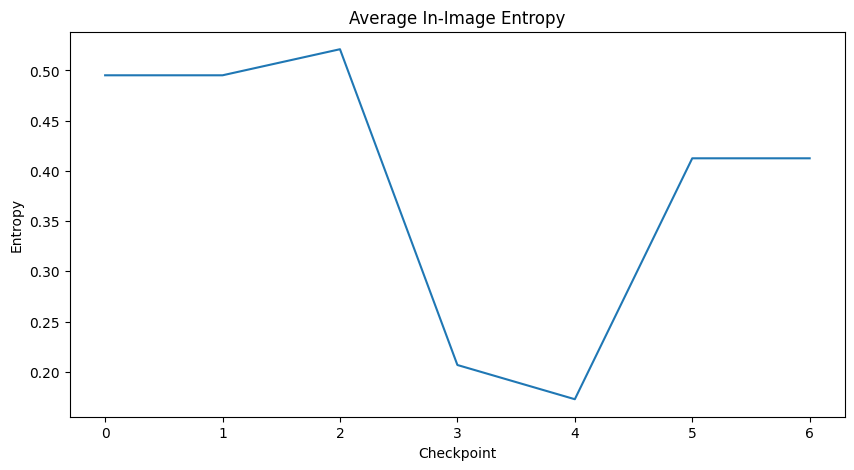

In [63]:
# class balance
entropies = []
for i in range(len(ckpts_top_images)):
    # each checkpoint
    imgs = np.array([img[0] for img in ckpts_top_images[i]])
    entropy = calculate_entropy(imgs)
    entropies.append(entropy)
plt.subplots(figsize=(10, 5))
plt.plot(entropies)
plt.xlabel("Checkpoint")
plt.ylabel("Entropy")
plt.title("Average In-Image Entropy")

Text(0.5, 1.0, 'Inter-Image Entropy')

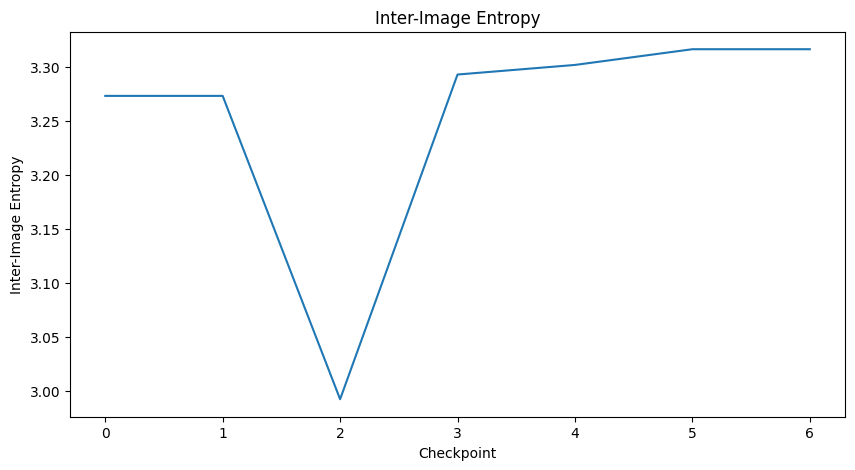

In [64]:
from scipy.spatial.distance import pdist
from scipy.stats import entropy

def image_pairwise_entropy(features):
    pairwise_distances = pdist(features, metric='cosine')
    distance_probs, _ = np.histogram(pairwise_distances, bins=30, density=True)
    distance_probs = distance_probs / np.sum(distance_probs)
    return entropy(distance_probs)

pw_entropies = []
for imgs in ckpts_top_images:
    imgs = np.array([torch.mean(img[0], dim=0).flatten() for img in imgs])
    ckpt_entropies = image_pairwise_entropy(imgs)
    pw_entropies.append(ckpt_entropies)
plt.subplots(figsize=(10, 5))
plt.plot(pw_entropies)
plt.xlabel("Checkpoint")
plt.ylabel("Inter-Image Entropy")
plt.title("Inter-Image Entropy")

inter image entropy increasing

Text(0, 0.5, 'Class Balances')

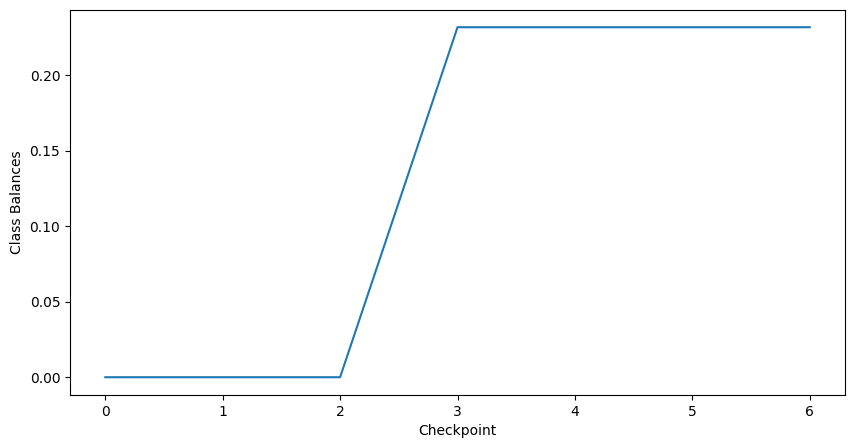

In [27]:
# 0.2 not increase yet; 0.23  0.252 sharp increase

# class balance
class_balances = []
for i in range(len(ckpts_top_images)):
    # each checkpoint
    imgs = np.array([img[1] for img in ckpts_top_images[i]])
    balance = calculate_class_balance(imgs)
    class_balances.append(balance)
plt.subplots(figsize=(10, 5))
plt.plot(class_balances)
plt.xlabel("Checkpoint")
plt.ylabel("Class Balances")

Z_imgs: (18, 18), volume: 5.744127931981276e+35
Z_imgs: (18, 18), volume: 1.6219548015774135e+36
Z_imgs: (18, 18), volume: 5.432349317995666e+34
Z_imgs: (18, 18), volume: 6.4823143111436796e+35
Z_imgs: (18, 18), volume: 4.46056709231369e+34
Z_imgs: (18, 18), volume: 2.929282656857905e+35
Z_imgs: (18, 18), volume: 2.1138889675847983e+35
1800


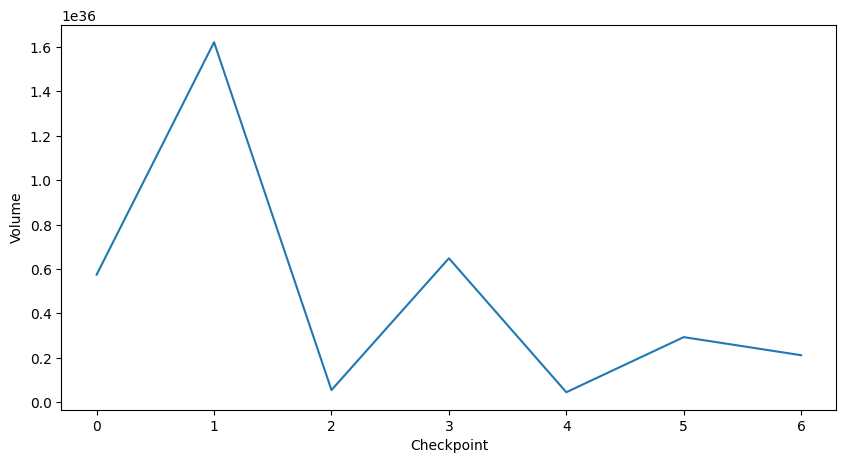

In [65]:
# 0.2 not increase yet; 0.23 ready to increase; 0.252 sharp increase; 0.4 oscillitate, 0.8, 1.0 no change; 0.6 oscillitate; 

from sklearn.decomposition import PCA

def volume(images):
    return np.sqrt(np.linalg.det(images.T@images))

def pca(x, k):
    x_std = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + 1e-8)
    pca = PCA(n_components=k)
    pca.fit(x_std)
    return pca.components_

volumes = []
for ckpt_imgs in ckpts_top_images:
    # print(ckpt_imgs[0][0].shape)
    ckpt_imgs = np.array([torch.mean(img[0], -1).flatten() for img in ckpt_imgs])
    W = pca(ckpt_imgs, 18)
    Z_imgs = ckpt_imgs @ W.T
    print(f"Z_imgs: {Z_imgs.shape}, volume: {volume(Z_imgs)}")
    # print(f"checkpoint: {ckpt_imgs.shape}")
    volumes.append(volume(Z_imgs))
plt.subplots(figsize=(10, 5))
plt.plot(volumes)
plt.xlabel("Checkpoint")
plt.ylabel("Volume")
print(len(np.load(DOGFISH_EMB_PATH, mmap_mode='r')["X_train"]))

For top 1% influential data, volume is larger at later checkpoints; 

**later checkpoints need higher diversity to increase accuracy**

(Checkpoint criterias trends are sensitive to number of top ninfluential data select at each checkpoint)

checkpoint 0 not increase yet; 

checkpoint 1, 2 rapid increase; 

checkpoint 3 oscillitate;

checkpoint 4, 5, 6 no change

Text(0, 0.5, 'Representiveness')

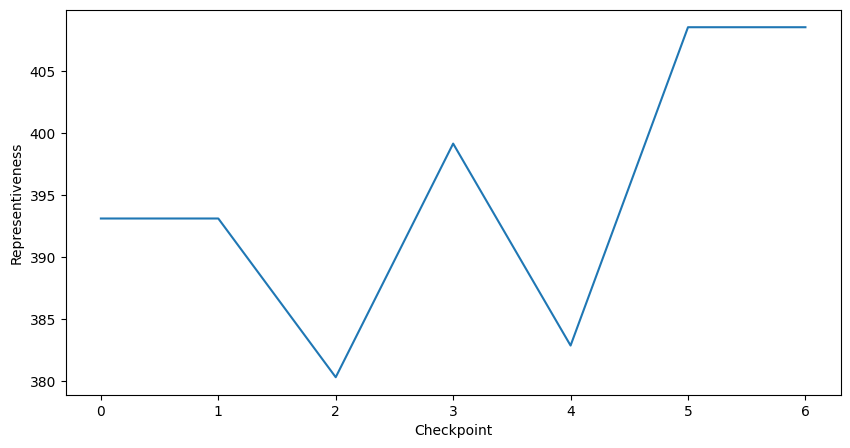

In [66]:
representivenesses = []
for i in range(len(ckpts_top_images)):
    # each checkpoint
    flatten_images = np.array([img[0].flatten() for img in ckpts_top_images[i]])
    repre = calc_representiveness(flatten_images)
    representivenesses.append(repre)

plt.subplots(figsize=(10, 5))
plt.plot(representivenesses)
plt.xlabel("Checkpoint")
plt.ylabel("Representiveness")